In [28]:
from sklearn.datasets import fetch_openml
import matplotlib.pyplot as plt
import numpy as np

directory = "../data"
mnist = fetch_openml('mnist_784', version=1, data_home=directory, as_frame=False, parser='liac-arff')

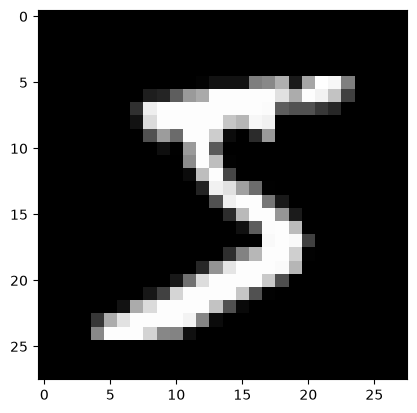

In [29]:
Xtrain = mnist.data[0:60000]
Ytrain = mnist.target[0:60000]

Xtest = mnist.data[60000:70000]
Ytest = mnist.target[60000:70000]
#Afficher une image du jeu de train
plt.imshow(Xtrain[0].reshape(28,28), cmap='gray')

random_seed = 1234


# 1. Classification d’un chiffre contre tous dans l’espace des pixels

Le sujet demande de faire varier le classifieur faible, le nombre d’étapes de boosting et les classes étudiées. Ici, les dix problèmes binaires sont traités simultanément : pour chaque chiffre `c` de 0 à 9, la cible vaut 1 pour `c` et 0 pour les neuf autres chiffres.

Le nombre d’étapes est fixé à 50 au maximum. AdaBoost peut toutefois s’arrêter avant cette limite lorsque l’ajout d’un nouvel estimateur ne permet plus d’obtenir un classifieur faible meilleur que le hasard.

Le calcul est parallélisé sur les cœurs du processeur avec `joblib`. Les estimateurs scikit-learn utilisés ici ne disposent pas d’une implémentation GPU directe ; utiliser le GPU nécessiterait de remplacer ces estimateurs par une autre bibliothèque et ne constituerait plus exactement la même expérience.


In [60]:
from IPython.display import display
from joblib import Parallel, delayed
import joblib
import os
from pathlib import Path
from sklearn.base import clone
from sklearn.ensemble import AdaBoostClassifier
from sklearn.linear_model import Perceptron
from sklearn.metrics import ConfusionMatrixDisplay, confusion_matrix, f1_score
from sklearn.preprocessing import StandardScaler
from sklearn.tree import DecisionTreeClassifier

# Les arbres utilisent les pixels normalisés dans [0, 1].
Xtrain_pixels = (Xtrain / 255.0).astype(np.float32)
Xtest_pixels = (Xtest / 255.0).astype(np.float32)
Ytrain_int = Ytrain.astype(int)
Ytest_int = Ytest.astype(int)
N_BOOSTING = 200

configurations = {
    'Perceptron': lambda: Perceptron(max_iter=1000, tol=1e-3, random_state=random_seed),
    'Stump': lambda: DecisionTreeClassifier(max_depth=1, random_state=random_seed),
    'Arbre profondeur 3': lambda: DecisionTreeClassifier(max_depth=3, random_state=random_seed),
    'Arbre profondeur 5': lambda: DecisionTreeClassifier(max_depth=5, random_state=random_seed),
    'Arbre profondeur 10': lambda: DecisionTreeClassifier(max_depth=10, random_state=random_seed),
}

# Les modèles scikit-learn utilisés ici sont CPU-only. Avec 24 cœurs,
# on entraîne 2 configurations en parallèle, chacune avec 10 chiffres.
N_JOBS_CONFIGURATIONS = 2
N_JOBS_CLASSIFIEURS = 10
N_JOBS_TOTAL = N_JOBS_CONFIGURATIONS * N_JOBS_CLASSIFIEURS

DOSSIER_MODELES = Path('modeles') / 'one_vs_all'
DOSSIER_MODELES.mkdir(parents=True, exist_ok=True)

def _slugifier(texte):
    return ''.join(car if car.isalnum() or car in '-_' else '_' for car in texte.lower())

def chemin_modele(nom, chiffre, espace):
    nom_fichier = f'{_slugifier(espace)}__{_slugifier(nom)}__chiffre_{chiffre}.joblib'
    return DOSSIER_MODELES / nom_fichier

def charger_ou_entrainer_un_chiffre(factory, nom, chiffre, X, y, n_estimators, espace):
    chemin = chemin_modele(nom, chiffre, espace)
    if chemin.is_file():
        try:
            modele = joblib.load(chemin)
            print(f"Chargé : {chemin.name}")
            return nom, chiffre, modele
        except Exception:
            print(f"Fichier invalide, nouvel entraînement : {chemin.name}")

    cible = (y == chiffre).astype(int)
    estimateur = factory()
    if 'random_state' in estimateur.get_params():
        estimateur.set_params(random_state=random_seed + chiffre)
    modele = AdaBoostClassifier(
        estimator=estimateur,
        n_estimators=n_estimators,
        learning_rate=1.0,
        random_state=random_seed + chiffre,
    )
    modele.fit(X, cible)
    joblib.dump(modele, chemin)
    print(f"Entraîné et sauvegardé : {chemin.name}")
    return nom, chiffre, modele

def entrainer_toutes_configurations(configurations, X, y, espace, n_estimators=N_BOOSTING):
    # Un seul pool évite le parallélisme imbriqué loky/threading.
    taches = [
        (nom, factory, chiffre)
        for nom, factory in configurations.items()
        for chiffre in range(10)
    ]
    resultats = Parallel(
        n_jobs=N_JOBS_TOTAL,
        backend='loky',
        max_nbytes='100M',
        mmap_mode='r',
    )(
        delayed(charger_ou_entrainer_un_chiffre)(factory, nom, chiffre, X, y, n_estimators, espace)
        for nom, factory, chiffre in taches
    )
    modeles = {nom: {} for nom in configurations}
    for nom, chiffre, modele in resultats:
        modeles[nom][chiffre] = modele
    return modeles

modeles_pixels = entrainer_toutes_configurations(
    configurations, Xtrain_pixels, Ytrain_int, espace='pixels'
)


## Résultats et matrices de confusion

Pour obtenir une prédiction multiclasse, on calcule le score de décision fourni par chacun des dix classifieurs, puis on retient le chiffre dont le score est maximal. Les matrices de confusion ci-dessous évaluent donc le système complet de dix classifieurs. Le F1-score macro est utilisé car il donne le même poids à chaque chiffre.


,Configuration,F1 macro multiclasse,F1 binaire moyen,Nombre moyen d’étapes
3,Arbre profondeur 5,0.981444,0.976652,200.0
4,Arbre profondeur 10,0.980013,0.967128,200.0
2,Arbre profondeur 3,0.972818,0.963353,200.0
1,Stump,0.889101,0.859504,200.0
0,Perceptron,0.876273,0.856943,15.7


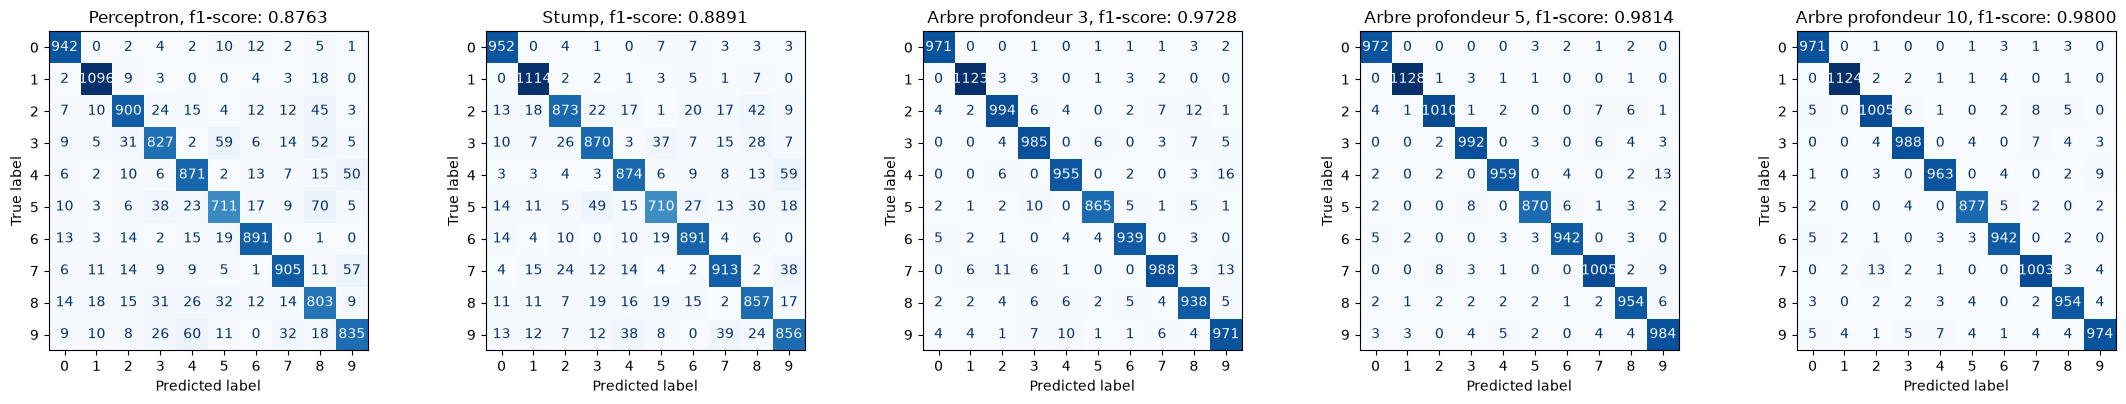

In [61]:
def scores_un_contre_tous(modeles, X):
    return np.column_stack([
        modeles[chiffre].decision_function(X)
        for chiffre in range(10)
    ])

def predire_un_contre_tous(modeles, X):
    return np.argmax(scores_un_contre_tous(modeles, X), axis=1)

resultats_pixels = []
predictions_pixels = {}
for nom, modeles in modeles_pixels.items():
    y_pred = predire_un_contre_tous(modeles, Xtest_pixels)
    predictions_pixels[nom] = y_pred
    f1_binaire = np.mean([
        f1_score(
            (Ytest_int == chiffre).astype(int),
            (modeles[chiffre].decision_function(Xtest_pixels) >= 0).astype(int),
            zero_division=0,
        )
        for chiffre in range(10)
    ])
    resultats_pixels.append({
        'Configuration': nom,
        'F1 macro multiclasse': f1_score(Ytest_int, y_pred, average='macro'),
        'F1 binaire moyen': f1_binaire,
        'Nombre moyen d’étapes': np.mean([len(modele.estimators_) for modele in modeles.values()]),
    })

resultats_pixels = pd.DataFrame(resultats_pixels).sort_values(
    'F1 macro multiclasse', ascending=False
)
display(resultats_pixels)

fig, axes = plt.subplots(1, len(modeles_pixels), figsize=(22, 4))
for ax, (nom, y_pred) in zip(axes, predictions_pixels.items()):
    matrice = confusion_matrix(Ytest_int, y_pred, labels=range(10))
    ConfusionMatrixDisplay(matrice, display_labels=range(10)).plot(
        ax=ax, cmap='Blues', colorbar=False
    )
    ax.set_title(f"{nom}, f1-score: {f1_score(Ytest_int, y_pred, average='macro'):.4f}")
plt.tight_layout()
plt.show()


### Bilan de la partie 1

Les tableaux et matrices de confusion permettent de comparer objectivement les configurations. Le stump constitue le classifieur faible le plus contraint : chaque estimateur ne teste qu’un seul seuil sur un pixel. Les arbres plus profonds peuvent représenter des règles plus complexes, mais ils sont aussi moins faibles ; il faut donc vérifier si l’amélioration est réelle ou si le boosting s’arrête rapidement.

Le perceptron fournit une séparation linéaire. S’il atteint rapidement une erreur faible, AdaBoost peut s’arrêter avant les 50 étapes demandées : `n_estimators=50` est une limite supérieure et non une garantie de 50 estimateurs effectivement entraînés.


# 2. Cartes de saillance dans l’espace des pixels

Une carte de saillance indique les pixels utilisés par le modèle pour distinguer un chiffre des autres. Pour les arbres, nous agrégeons les importances des variables de chaque estimateur faible, pondérées par le poids AdaBoost de cet estimateur. Pour le perceptron, nous agrégeons de la même façon les valeurs absolues des coefficients.

On affiche ici les cartes associées au classifieur « chiffre 1 contre tous », mais la fonction peut être appelée pour n’importe quel chiffre.


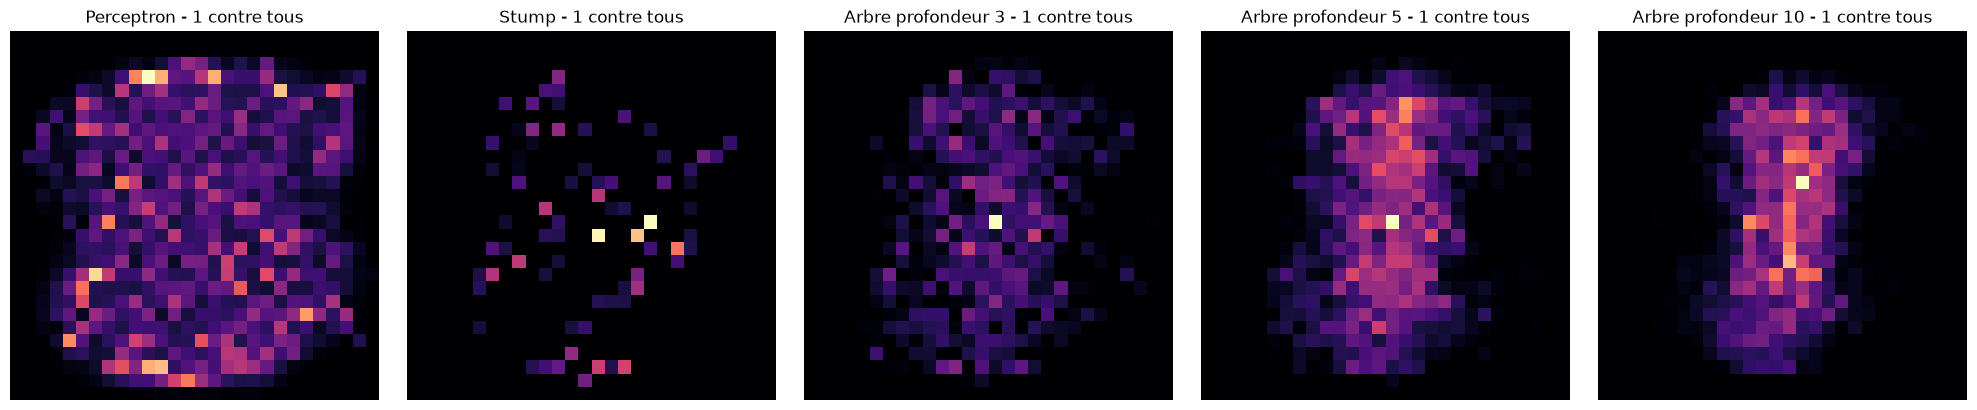

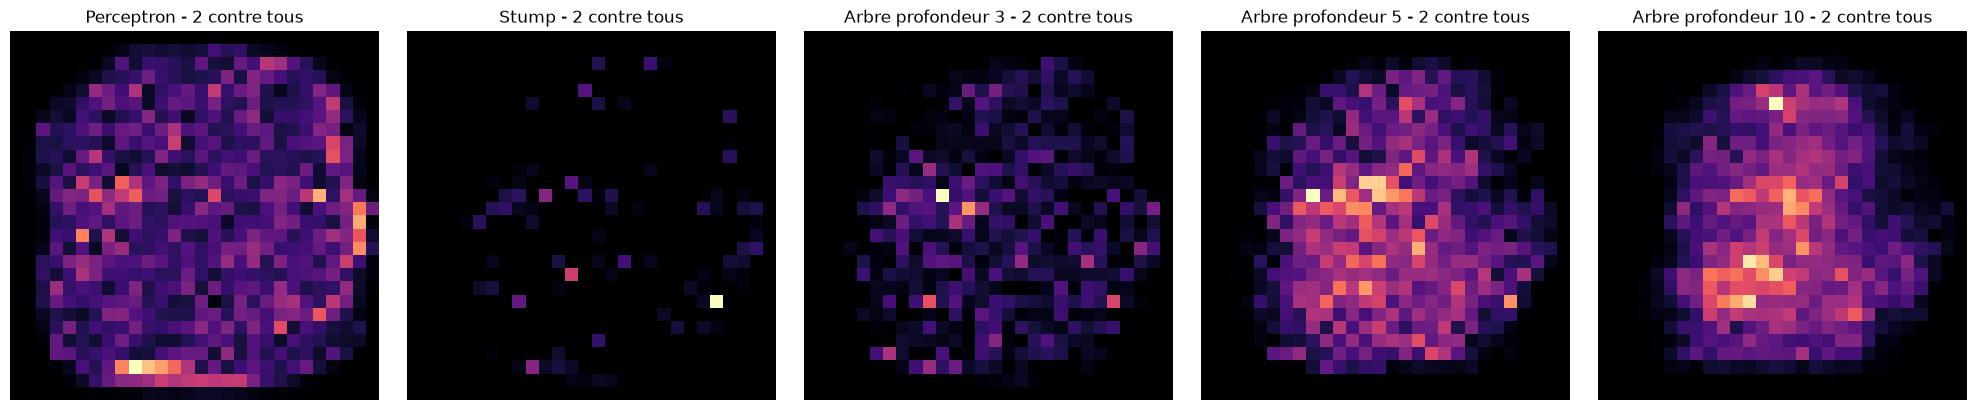

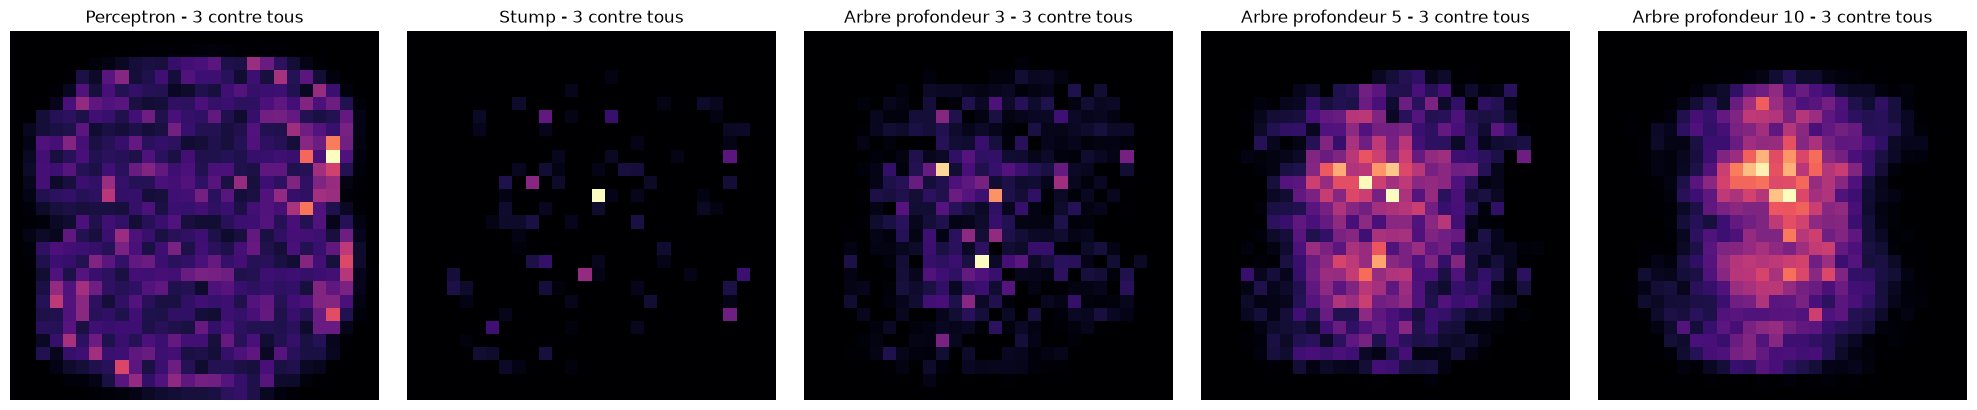

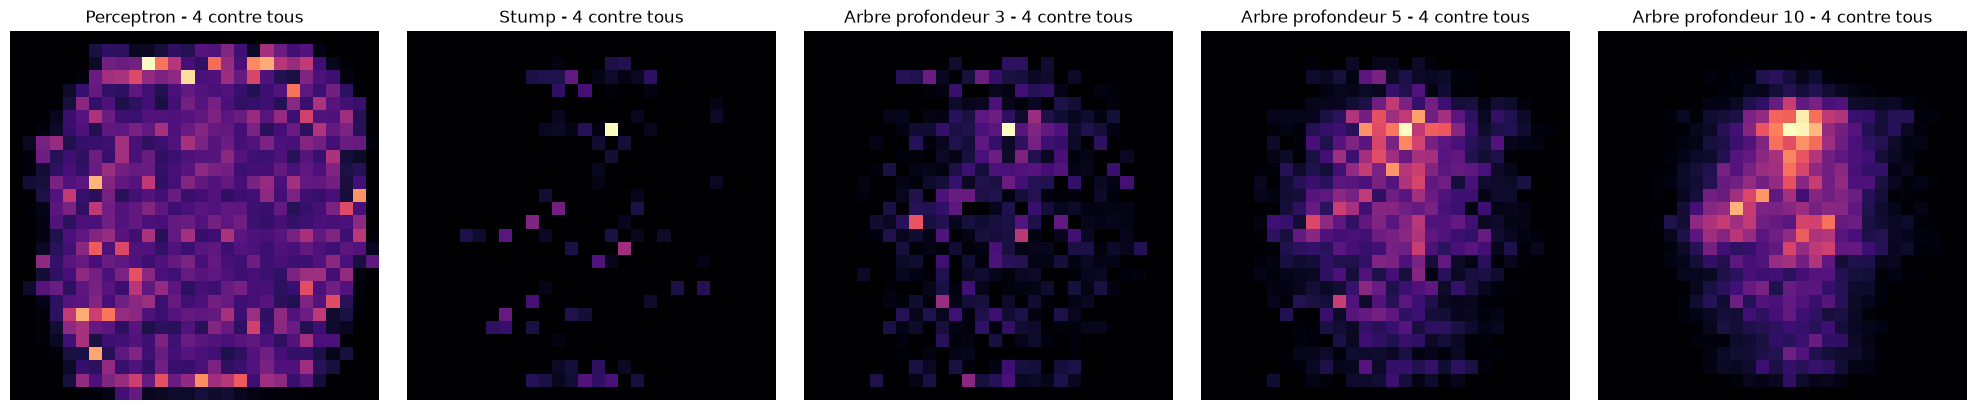

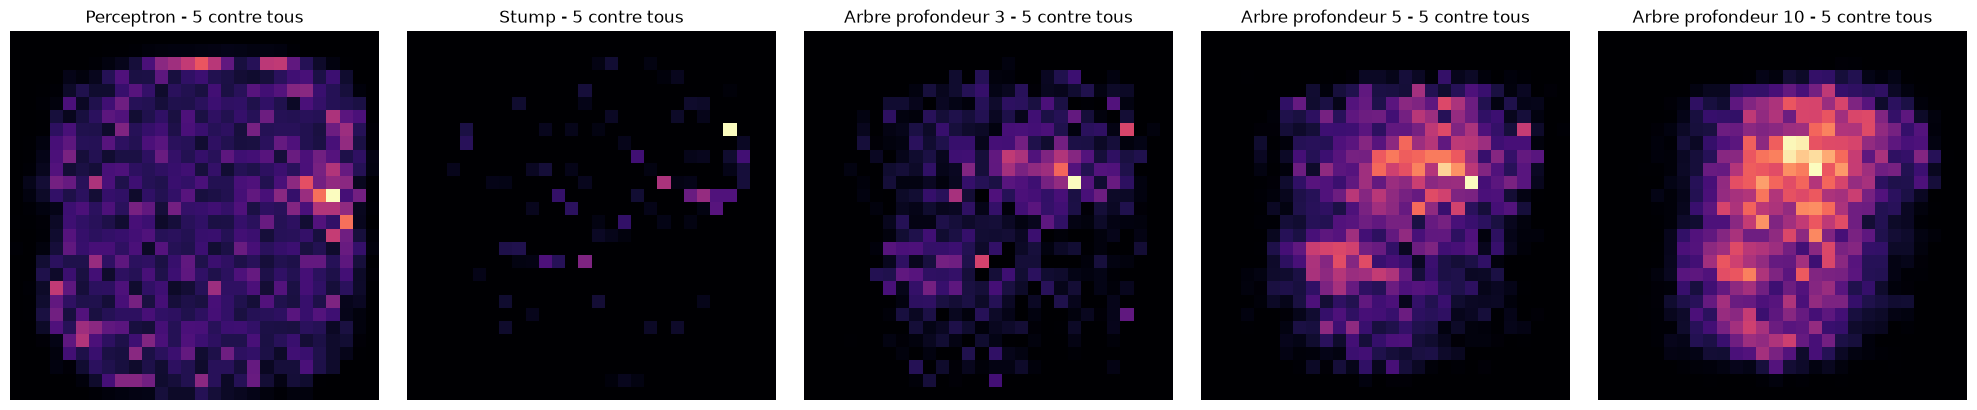

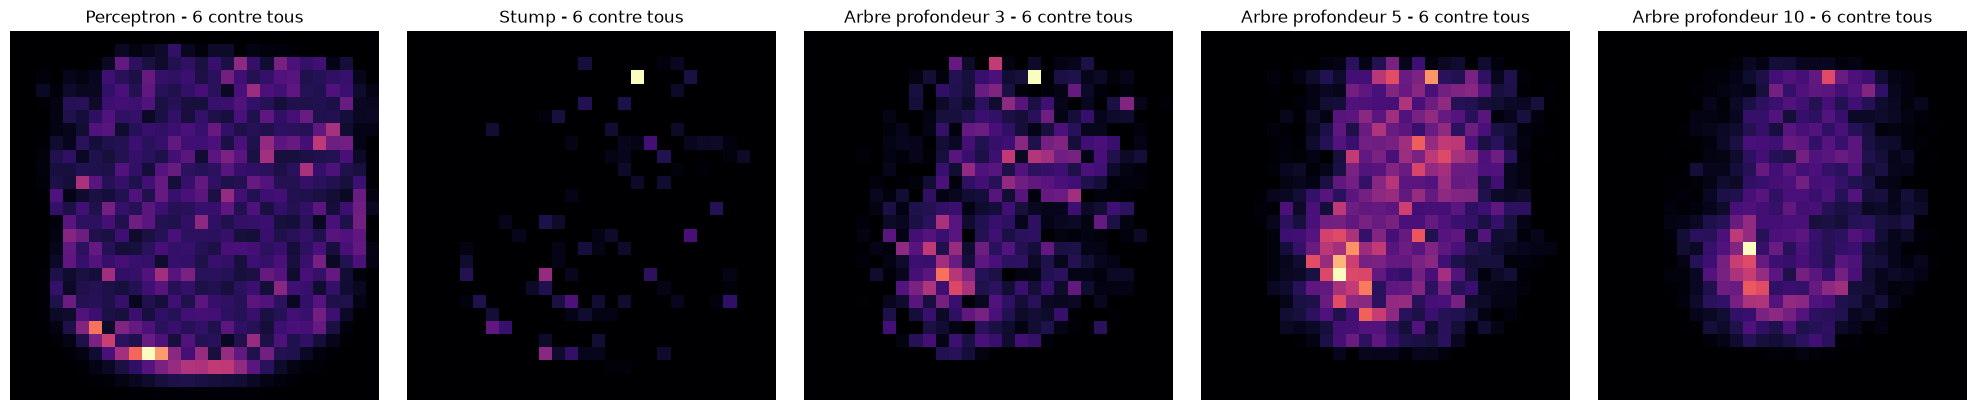

In [62]:
def carte_saillance(modele):
    importance = np.zeros(Xtrain_pixels.shape[1], dtype=float)
    poids = modele.estimator_weights_[:len(modele.estimators_)]
    for estimateur, poids_estimateur in zip(modele.estimators_, poids):
        if hasattr(estimateur, 'feature_importances_'):
            contribution = estimateur.feature_importances_
        elif hasattr(estimateur, 'coef_'):
            contribution = np.abs(np.asarray(estimateur.coef_)).ravel()
        else:
            raise TypeError(f'Estimateur non pris en charge : {type(estimateur).__name__}')
        importance += abs(poids_estimateur) * contribution
    maximum = importance.max()
    return importance.reshape(28, 28) / maximum if maximum > 0 else importance.reshape(28, 28)

def afficher_cartes_saillance(modeles, chiffre=1):
    fig, axes = plt.subplots(1, len(modeles), figsize=(20, 4))
    for ax, (nom, ensemble) in zip(axes, modeles.items()):
        ax.imshow(carte_saillance(ensemble[chiffre]), cmap='magma')
        ax.set_title(f'{nom} - {chiffre} contre tous')
        ax.axis('off')
    plt.tight_layout()
    plt.show()

afficher_cartes_saillance(modeles_pixels, chiffre=1)
afficher_cartes_saillance(modeles_pixels, chiffre=2)
afficher_cartes_saillance(modeles_pixels, chiffre=3)
afficher_cartes_saillance(modeles_pixels, chiffre=4)
afficher_cartes_saillance(modeles_pixels, chiffre=5)
afficher_cartes_saillance(modeles_pixels, chiffre=6)


### Interprétation des cartes de saillance

Les stumps font apparaître des zones ponctuelles, car chaque estimateur faible sélectionne un nombre très limité de pixels. Les arbres utilisent généralement des régions plus étendues, tandis que le perceptron peut produire une carte plus diffuse. Les zones les plus marquées correspondent aux parties de l’image qui distinguent le chiffre étudié de la majorité des autres chiffres. Cette interprétation doit rester prudente : une importance élevée signale une corrélation utile au modèle, et non une causalité.


# 3. Répétition avec un embedding de dimension 64

Conformément au sujet, nous apprenons un embedding 784 → 64 → 784 avec un autoencodeur. Les dix classifieurs AdaBoost sont ensuite réentraînés dans l’espace latent de dimension 64, avec exactement les mêmes configurations et le même nombre maximal d’étapes que dans l’espace des pixels.


In [63]:
from sklearn.exceptions import ConvergenceWarning
from sklearn.neural_network import MLPRegressor
import warnings

autoencodeur = MLPRegressor(
    hidden_layer_sizes=(64,),
    activation='relu',
    max_iter=30,
    random_state=random_seed,
)
with warnings.catch_warnings():
    warnings.simplefilter('ignore', ConvergenceWarning)
    autoencodeur.fit(Xtrain_pixels, Xtrain_pixels)

W_enc = autoencodeur.coefs_[0]
b_enc = autoencodeur.intercepts_[0]

def encoder(X):
    return np.maximum(X @ W_enc + b_enc, 0)

Ztrain = encoder(Xtrain_pixels)
Ztest = encoder(Xtest_pixels)
print('Dimensions de l’embedding :', Ztrain.shape, Ztest.shape)

modeles_embedding = entrainer_toutes_configurations(
    configurations, Ztrain, Ytrain_int, espace='embedding'
)


Dimensions de l’embedding : (60000, 64) (10000, 64)


,Configuration,F1 macro multiclasse,Nombre moyen d’étapes
4,Arbre profondeur 10,0.971032,200.0
3,Arbre profondeur 5,0.966702,200.0
2,Arbre profondeur 3,0.948378,200.0
1,Stump,0.879314,200.0
0,Perceptron,0.855624,7.1


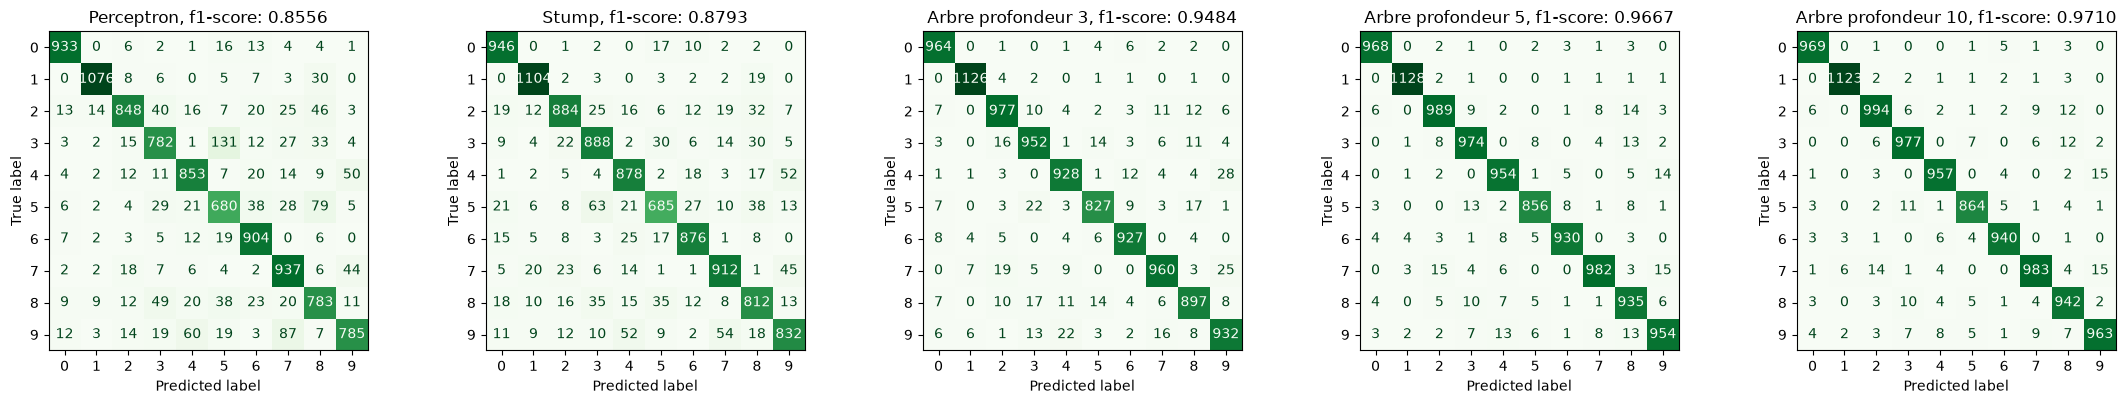

In [64]:
resultats_embedding = []
predictions_embedding = {}
for nom, modeles in modeles_embedding.items():
    y_pred = predire_un_contre_tous(modeles, Ztest)
    predictions_embedding[nom] = y_pred
    resultats_embedding.append({
        'Configuration': nom,
        'F1 macro multiclasse': f1_score(Ytest_int, y_pred, average='macro'),
        'Nombre moyen d’étapes': np.mean([len(modele.estimators_) for modele in modeles.values()]),
    })

resultats_embedding = pd.DataFrame(resultats_embedding).sort_values(
    'F1 macro multiclasse', ascending=False
)
display(resultats_embedding)

fig, axes = plt.subplots(1, len(modeles_embedding), figsize=(22, 4))
for ax, (nom, y_pred) in zip(axes, predictions_embedding.items()):
    matrice = confusion_matrix(Ytest_int, y_pred, labels=range(10))
    ConfusionMatrixDisplay(matrice, display_labels=range(10)).plot(
        ax=ax, cmap='Greens', colorbar=False
    )
    ax.set_title(f"{nom}, f1-score: {f1_score(Ytest_int, y_pred, average='macro'):.4f}")
plt.tight_layout()
plt.show()


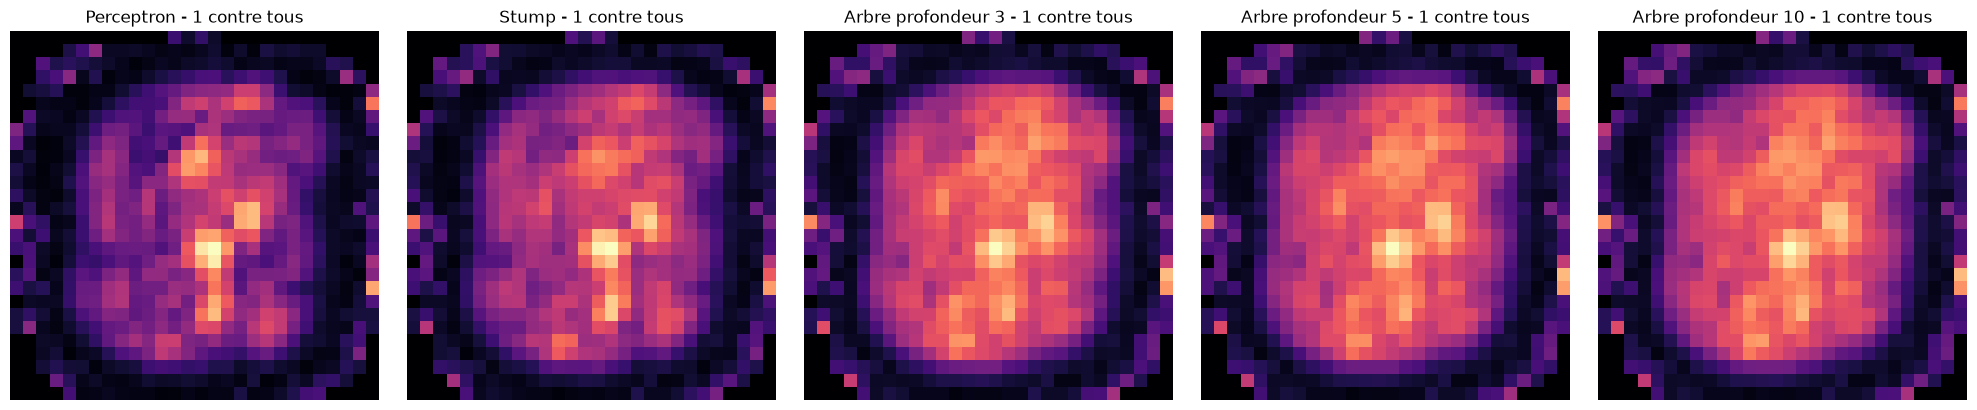

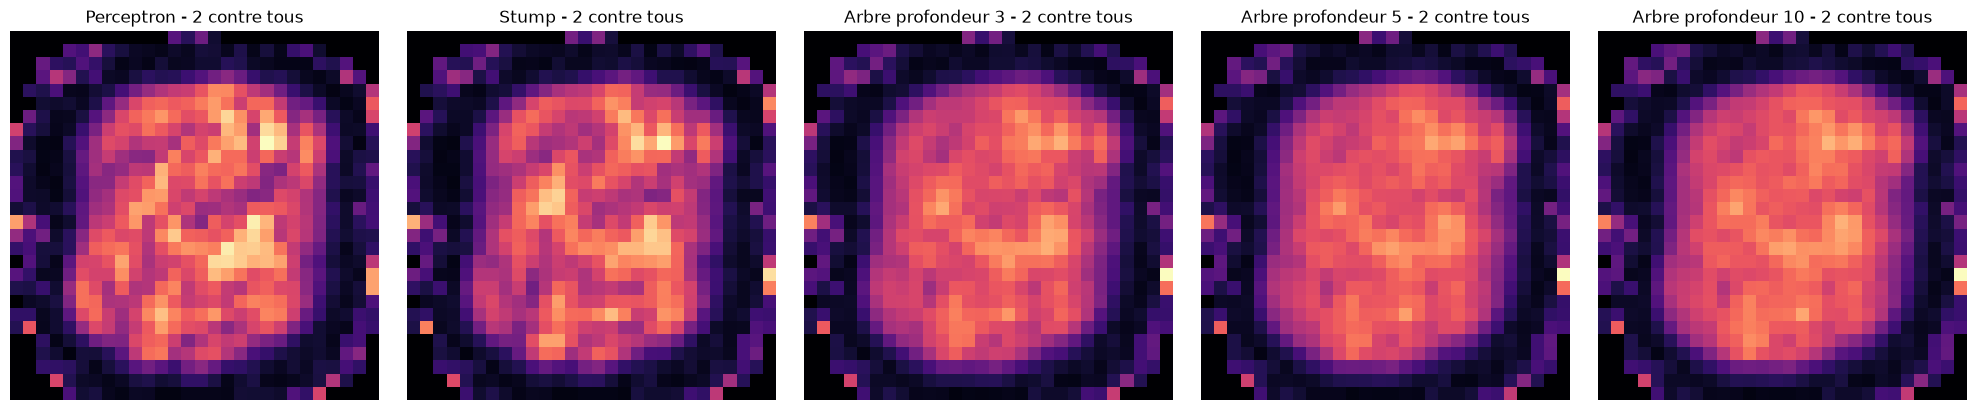

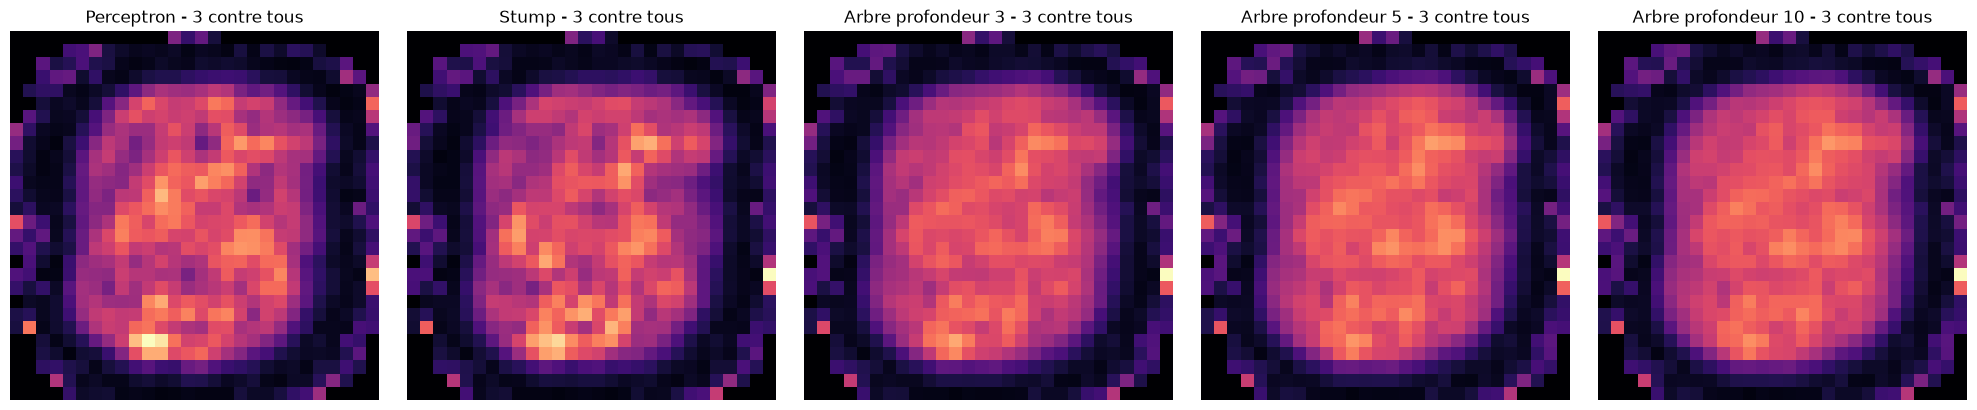

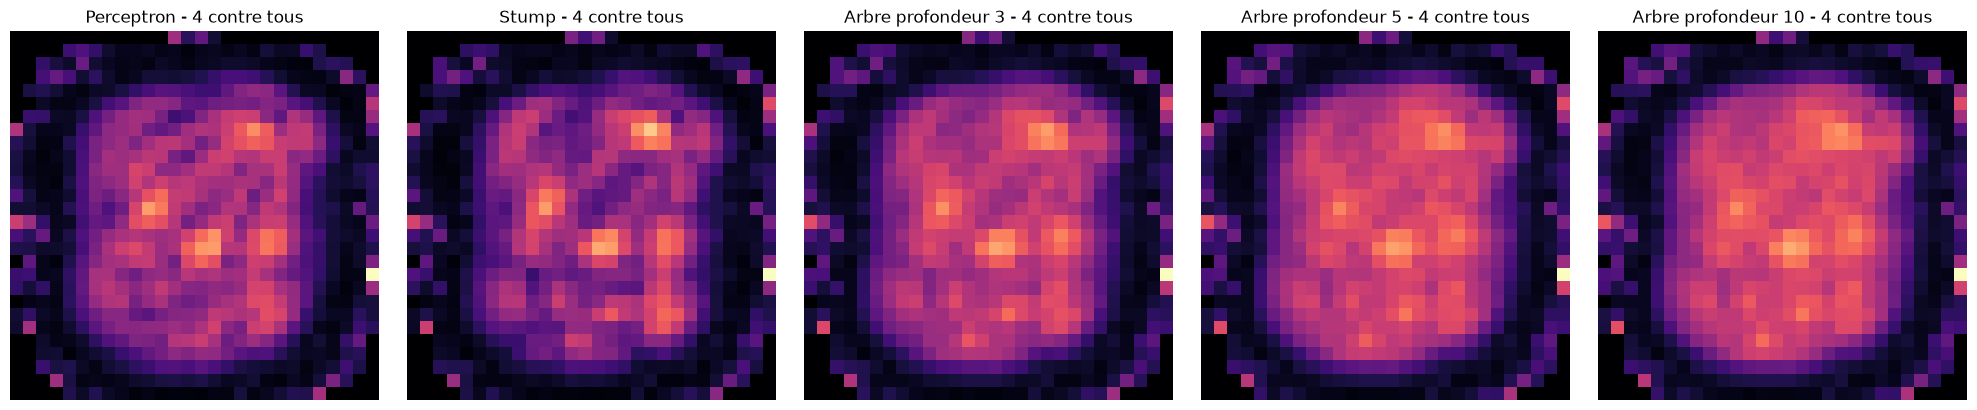

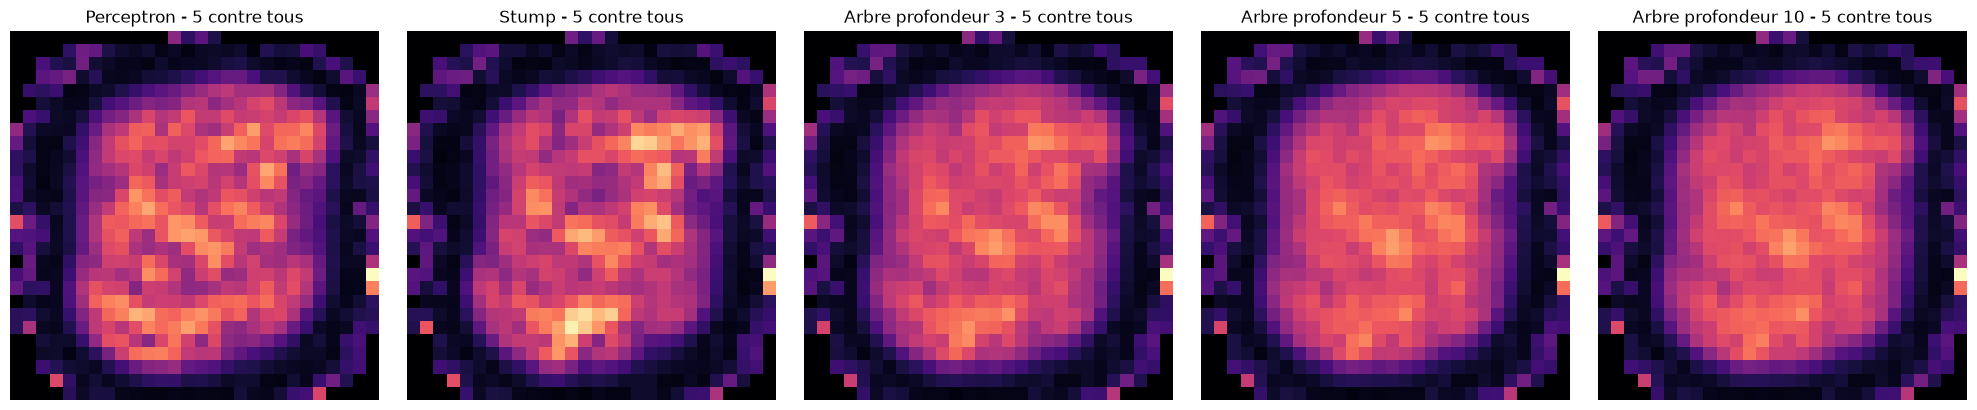

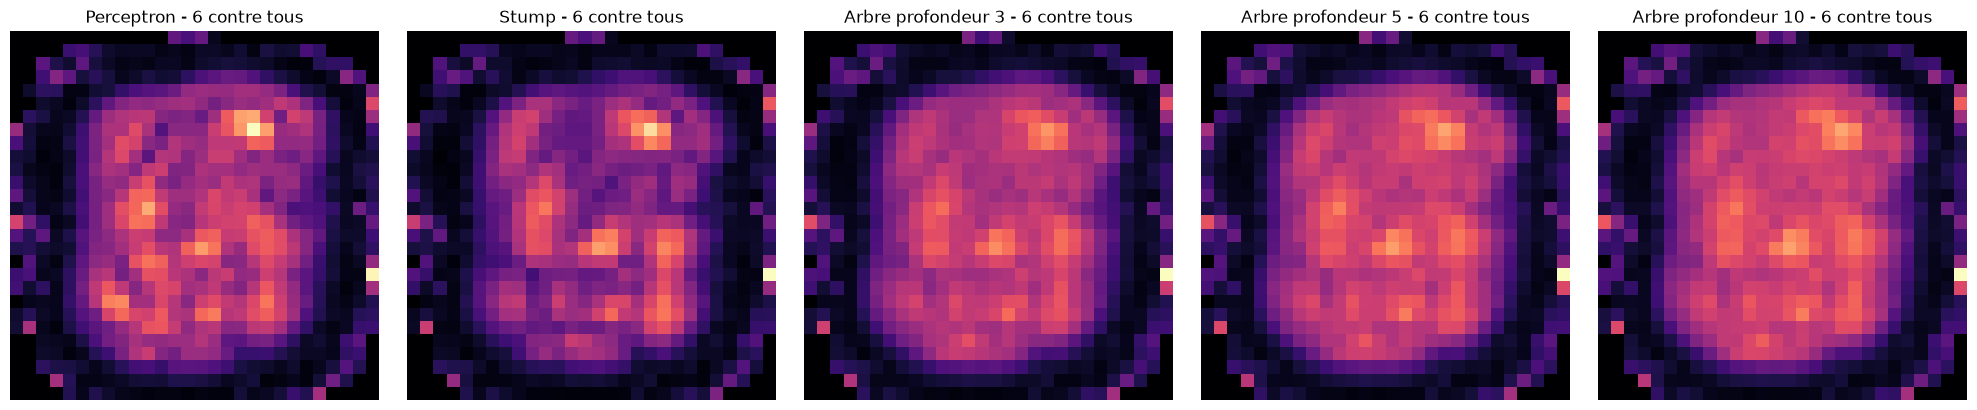

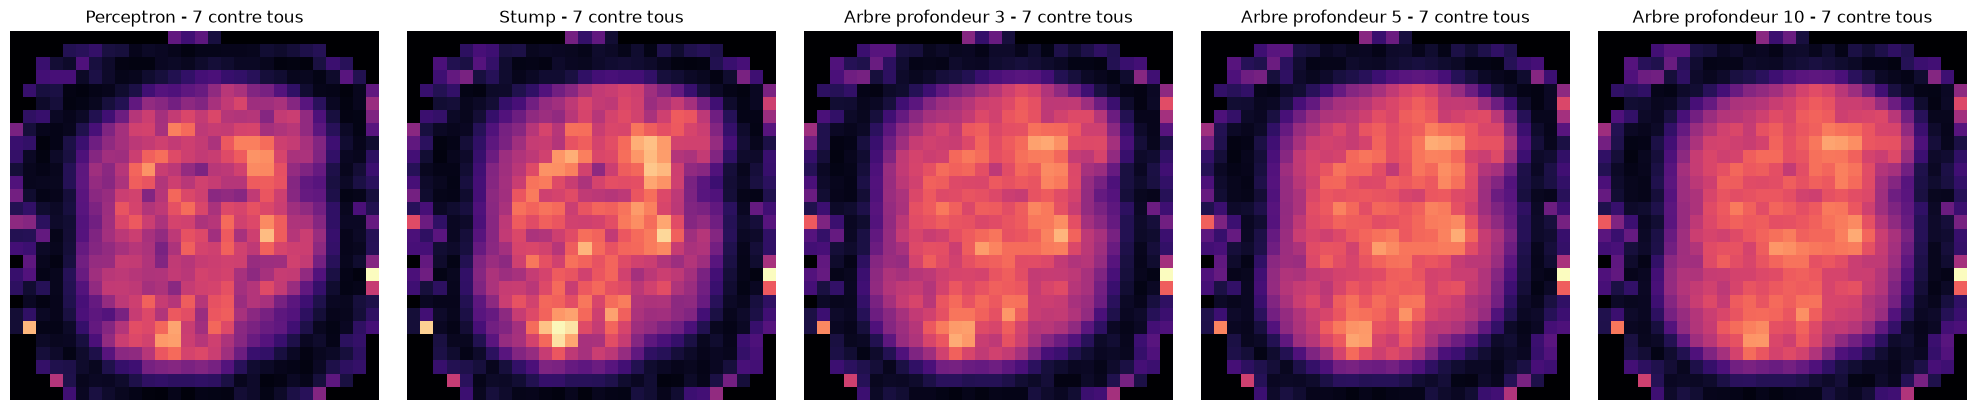

In [65]:
def gradcam_embedding(modele, X_cible, chiffre, nombre_exemples=200):
    """Rétroprojecte les activités latentes de l'encodeur vers les pixels.

    Pour un échantillon x, z = ReLU(W_enc.T @ x + b_enc). Les neurones
    latents identifiés par AdaBoost sont pondérés, puis rétroprojetés avec
    les poids de la couche d'encodage afin d'obtenir une carte 28 x 28.
    """
    indices = np.flatnonzero(Ytest_int == chiffre)
    if len(indices) == 0:
        raise ValueError(f'Aucun exemple test pour le chiffre {chiffre}')
    indices = indices[:nombre_exemples]
    X_cible = X_cible[indices]

    z_cible = encoder(X_cible)
    poids_adaboost = modele.estimator_weights_[:len(modele.estimators_)]
    gradients_latents = np.zeros(Ztrain.shape[1], dtype=float)

    for estimateur, poids_estimateur in zip(modele.estimators_, poids_adaboost):
        if hasattr(estimateur, 'coef_'):
            # Perceptron : gradient différentiable exact par rapport aux neurones latents.
            contribution = np.asarray(estimateur.coef_).ravel()
        elif hasattr(estimateur, 'feature_importances_'):
            # Arbre/stump : approximation par l’importance des neurones latents.
            contribution = estimateur.feature_importances_
        else:
            raise TypeError(f'Estimateur non pris en charge : {type(estimateur).__name__}')
        gradients_latents += poids_estimateur * contribution

    # GradCAM : moyenne des gradients pondérés par les activations latentes.
    poids_canaux = np.mean(z_cible * gradients_latents, axis=0)
    importance_latente = np.maximum(poids_canaux, 0)

    carte = np.abs(W_enc) @ importance_latente
    carte = carte - carte.min()
    maximum = carte.max()
    if maximum > 0:
        carte = carte / maximum
    return carte.reshape(28, 28)


def afficher_cartes_gradcam_embedding(modeles, chiffre=1):
    fig, axes = plt.subplots(1, len(modeles), figsize=(20, 4))
    for ax, (nom, ensemble) in zip(axes, modeles.items()):
        carte = gradcam_embedding(ensemble[chiffre], Xtest_pixels, chiffre)
        ax.imshow(carte, cmap='magma')
        ax.set_title(f'{nom} - {chiffre} contre tous')
        ax.axis('off')
    plt.tight_layout()
    plt.show()


afficher_cartes_gradcam_embedding(modeles_embedding, chiffre=1)
afficher_cartes_gradcam_embedding(modeles_embedding, chiffre=2)
afficher_cartes_gradcam_embedding(modeles_embedding, chiffre=3)
afficher_cartes_gradcam_embedding(modeles_embedding, chiffre=4)
afficher_cartes_gradcam_embedding(modeles_embedding, chiffre=5)
afficher_cartes_gradcam_embedding(modeles_embedding, chiffre=6)
afficher_cartes_gradcam_embedding(modeles_embedding, chiffre=7)


### Bilan de la partie 3

La comparaison entre `resultats_pixels` et `resultats_embedding` mesure l’effet de la réduction de la description de 784 à 64 variables. Une baisse du F1-score indique que l’embedding a supprimé de l’information utile à la discrimination ; un score comparable signifie que la représentation compacte a conservé l’essentiel de l’information.

Pour les cartes de saillance de l’embedding, on mesure d’abord les activités des neurones cachés sur les exemples test du chiffre étudié : $z = \mathrm{ReLU}(W_{enc}^T x+b_{enc})$. AdaBoost identifie ensuite les neurones latents les plus utiles. Pour un perceptron, les coefficients servent de gradient différentiable ; pour un arbre ou un stump, l’importance des variables joue le rôle de gradient d’importance. Ces poids sont multipliés par les activités $z$, moyennés sur les exemples, puis rétroprojetés dans les pixels avec $|W_{enc}|$. Cette méthode reprend le principe de GradCAM : pondération des cartes d’activations latentes suivie d’une rétroprojection dans l’espace d’entrée.

Cette rétroprojection reste une approximation pour les arbres, qui ne fournissent pas de gradient différentiable comme un réseau neuronal. Elle permet néanmoins d’obtenir une carte interprétable dans les 784 pixels originaux.


# 4. Évolution du F1-score pour les dix problèmes « chiffre contre tous »

Pour chaque chiffre de 0 à 9, la courbe présente le F1-score binaire obtenu après chaque étape de boosting. Les traits pleins correspondent aux pixels, tandis que les traits en pointillés correspondent à l’embedding. Les couleurs indiquent le classifieur faible utilisé.


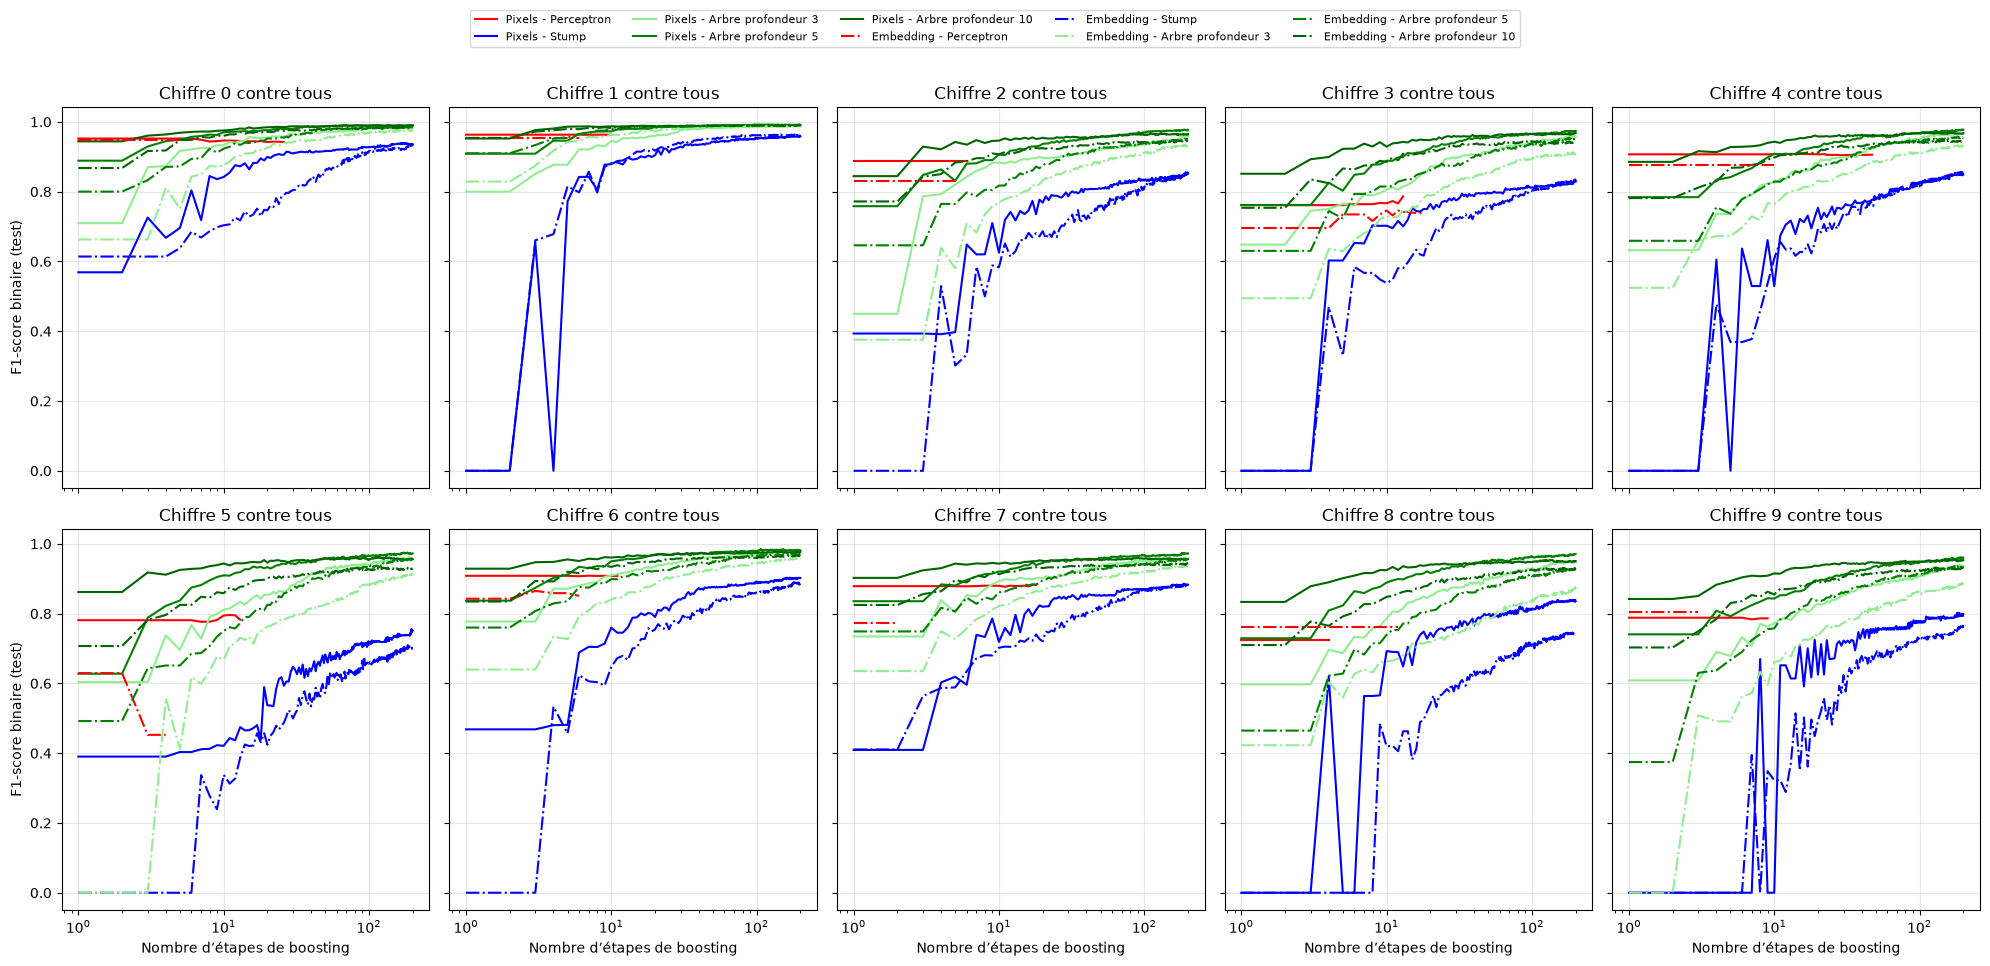


Chiffre 0 contre tous
Pixels - Perceptron             F1 = 0.9422
Pixels - Stump                  F1 = 0.9356
Pixels - Arbre profondeur 3     F1 = 0.9841
Pixels - Arbre profondeur 5     F1 = 0.9893
Pixels - Arbre profondeur 10    F1 = 0.9903
Embedding - Perceptron          F1 = 0.9473
Embedding - Stump               F1 = 0.9322
Embedding - Arbre profondeur 3  F1 = 0.9750
Embedding - Arbre profondeur 5  F1 = 0.9846
Embedding - Arbre profondeur 10 F1 = 0.9840

Chiffre 1 contre tous
Pixels - Perceptron             F1 = 0.9628
Pixels - Stump                  F1 = 0.9584
Pixels - Arbre profondeur 3     F1 = 0.9877
Pixels - Arbre profondeur 5     F1 = 0.9916
Pixels - Arbre profondeur 10    F1 = 0.9894
Embedding - Perceptron          F1 = 0.9543
Embedding - Stump               F1 = 0.9618
Embedding - Arbre profondeur 3  F1 = 0.9899
Embedding - Arbre profondeur 5  F1 = 0.9912
Embedding - Arbre profondeur 10 F1 = 0.9898

Chiffre 2 contre tous
Pixels - Perceptron             F1 = 0.8885
Pixels 

In [66]:
def couleur_classifieur(nom):
    nom_minuscule = nom.lower()
    if "stump" in nom_minuscule:
        return "b"
    if "arbre" in nom_minuscule and "3" in nom_minuscule:
        return "lightgreen"
    if "arbre" in nom_minuscule and "5" in nom_minuscule:
        return "green"
    if "arbre" in nom_minuscule and "10" in nom_minuscule:
        return "darkgreen"
    if "perceptron" in nom_minuscule:
        return "red"
    return "black"

def afficher_f1_final(chiffre, ensemble_pixels, ensemble_embedding):
    print(f"\nChiffre {chiffre} contre tous")
    for nom, modeles in ensemble_pixels.items():
        modele = modeles[chiffre]
        y_pred = modele.predict(Xtest_pixels)
        f1 = f1_score((Ytest_int == chiffre).astype(int), y_pred)
        print(f"Pixels - {nom:22s} F1 = {f1:.4f}")
    for nom, modeles in ensemble_embedding.items():
        modele = modeles[chiffre]
        y_pred = modele.predict(Ztest)
        f1 = f1_score((Ytest_int == chiffre).astype(int), y_pred)
        print(f"Embedding - {nom:19s} F1 = {f1:.4f}")

fig, axes = plt.subplots(2, 5, figsize=(20, 9), sharex=True, sharey=True)
axes = axes.ravel()

for chiffre, ax in enumerate(axes):
    y_reel = (Ytest_int == chiffre).astype(int)
    # pour les graph de la ligne du haut on enleve le titre de l'axe des x, pour toute les colonnes sauf la gauche on enleve le titre de l'axe des y

    for nom, modeles in modeles_pixels.items():
        modele = modeles[chiffre]
        f1_etapes = [
            f1_score(y_reel, y_pred)
            for y_pred in modele.staged_predict(Xtest_pixels)
        ]
        ax.plot(
            range(1, len(f1_etapes) + 1),
            f1_etapes,
            label=f"Pixels - {nom}",
            linestyle="-",
            color=couleur_classifieur(nom),
        )


    for nom, modeles in modeles_embedding.items():
        modele = modeles[chiffre]
        f1_etapes = [
            f1_score(y_reel, y_pred)
            for y_pred in modele.staged_predict(Ztest)
        ]
        ax.plot(
            range(1, len(f1_etapes) + 1),
            f1_etapes,
            label=f"Embedding - {nom}",
            linestyle="-.",
            color=couleur_classifieur(nom),
        )

    ax.set_xscale("log")
    ax.set_title(f"Chiffre {chiffre} contre tous")
    ax.set_xlabel("Nombre d’étapes de boosting")
    ax.set_ylabel("F1-score binaire (test)")
    ax.grid(alpha=0.3)
    if ax == axes[0]:
        ax.set_title(f"Chiffre {chiffre} contre tous")
    if ax != axes[0] and ax != axes[5]:
        ax.set_ylabel("")
    if any(ax == axes[i] for i in range(0, 5)):
        ax.set_xlabel("")

handles, labels = axes[-1].get_legend_handles_labels()
fig.legend(handles, labels, loc="lower center", ncol=5, fontsize=8, bbox_to_anchor=(0.5, 1.02))
plt.tight_layout()
plt.show()

for chiffre in range(10):
    afficher_f1_final(chiffre, modeles_pixels, modeles_embedding)
